In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles available:")
print(os.listdir())

Current Working Directory:
C:\Users\Divakar

Files available:
['.anaconda', '.arduinoIDE', '.cache', '.codex', '.conda', '.copilot', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.Ld9VirtualBox', '.m2', '.matplotlib', '.ms-ad', '.opera', '.ssh', '.streamlit', '.vscode', '.vscode-shared', 'AIML.txt', 'AI_vs_ML_vs_Deep_Learning.ipynb', 'anaconda3', 'AppData', 'Application Data', 'boxplot.png', 'breadth first search.py', 'CLOAK_CV-VISION', 'Contacts', 'Cookies', 'CrossDevice', 'customer_churn_prediction.ipynb', 'Customer_Churn_Prediction_and_Retention_Analysis.ipynb', 'customer_segment_analysis.csv', 'customer_spending_cleaned.csv', 'customer_spending_segments.csv', 'dataset.csv', 'Day-11-NumPy-Student-Marks.ipynb', 'Day-12-NumPy-Array-Operations.ipynb', 'Day-13-NumPy-Data-Filtering.ipynb', 'Day_14_NumPy_Matrix_Operations.ipynb', 'Day_15_NumPy_Statistical_Analysis.ipynb', 'Day_22_Handle_Missing_Values.ipynb', 'Day_23_Duplicate_Data_Removal.ipynb', 'Day_34_AI_Cust

In [5]:
import os

print(os.listdir(r"C:\Users"))

['All Users', 'Default', 'Default User', 'desktop.ini', 'Divakar', 'Public']


In [7]:
import os

print("Windows Username:", os.getlogin())

downloads_path = os.path.join(
    os.path.expanduser("~"),
    "Downloads"
)

print("Downloads Folder:", downloads_path)

print("\nFiles in Downloads:")
print(os.listdir(downloads_path))

Windows Username: Divakar
Downloads Folder: C:\Users\Divakar\Downloads

Files in Downloads:
['#04BE2027 - JAYEM AUTOMOTIVES.pdf', '#27BE2027 - GRIDSYNC.pdf', '.history', '.opera', '.pdf', '0th Review - Team Divakar (1) (1).pptx', '0th Review - Team Divakar (1) (2).pptx', '0th Review - Team Divakar (1) (3) (1).pptx', '0th Review - Team Divakar (1) (3).pptx', '0th Review - Team Divakar (1) (4).pptx', '0th Review - Team Divakar (1).pptx', '0th Review - Team Divakar (2).pptx', '0th Review - Team Divakar (3).pptx', '0th Review - Team Divakar.pptx', '1 Month Embedded System.docx', '1000165485.jpg', '1000286429 (1).pdf', '10th Marksheet - Divakar.pdf', '11th & 12th Marksheet - Divakar.pdf', '12th Marksheet.pdf', '152952215.jpg', '1788199213504_SIH Ideate Template.pdf', '2nd unit 2. Principal Upanishads, Bhagavad Gita and Yoga Vasishtha.pdf', '3464230.png', '4th Unit Communication.pdf', '4th unit kaivalya pada Tamil (1).pdf', '4th unit kaivalya pada Tamil.pdf', '4TH UNIT SADHANA PADA TAMIL.pdf

In [9]:
import os

search_locations = [
    r"C:\Users\Divakar\Downloads",
    r"C:\Users\Divakar\Desktop",
    r"C:\Users\Divakar\Documents"
]

for folder in search_locations:
    print("\nSearching:", folder)

    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            if "Online Retail.xlsx" in files:
                print("FOUND:", os.path.join(root, "Online Retail.xlsx"))


Searching: C:\Users\Divakar\Downloads

Searching: C:\Users\Divakar\Desktop

Searching: C:\Users\Divakar\Documents


In [11]:
import pandas as pd
from tkinter import Tk, filedialog

root = Tk()
root.withdraw()
root.attributes('-topmost', True)

file_path = filedialog.askopenfilename(
    title="Select Online Retail Dataset",
    filetypes=[("Excel Files", "*.xlsx *.xls")]
)

root.destroy()

print("Selected file:", file_path)

Selected file: 


In [12]:
import os
import requests

# Create dataset folder
os.makedirs("data", exist_ok=True)

# Official UCI dataset download
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(url, timeout=120)

if response.status_code == 200:
    with open("data/online_retail.zip", "wb") as file:
        file.write(response.content)

    print("Dataset downloaded successfully!")
    print("File size:", round(len(response.content) / (1024 * 1024), 2), "MB")
else:
    print("Download failed:", response.status_code)
    

Dataset downloaded successfully!
File size: 22.62 MB


In [13]:
import zipfile

zip_path = "data/online_retail.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("data")

print("Dataset extracted successfully!")
print(os.listdir("data"))

Dataset extracted successfully!
['Online Retail.xlsx', 'online_retail.zip']


In [29]:
df = pd.read_excel("data/Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [24]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

Statistical Summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [25]:
print("Missing Values:")
display(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Duplicate Records:
5268


In [26]:
df_clean = df.copy()

# Remove missing Customer IDs
df_clean = df_clean.dropna(subset=['CustomerID'])

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove cancelled transactions
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

# Remove invalid quantities
df_clean = df_clean[df_clean['Quantity'] > 0]

# Remove invalid prices
df_clean = df_clean[df_clean['UnitPrice'] > 0]

# Convert CustomerID to integer
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# Convert InvoiceDate
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# Calculate transaction amount
df_clean['TotalAmount'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

print("Data Cleaning Completed!")

print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

display(df_clean.head())

Data Cleaning Completed!
Original Dataset: (541909, 8)
Cleaned Dataset: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [27]:
print("Total Customers:",
      df_clean['CustomerID'].nunique())

print("Total Products:",
      df_clean['StockCode'].nunique())

print("Total Transactions:",
      df_clean['InvoiceNo'].nunique())

print("Total Revenue:",
      round(df_clean['TotalAmount'].sum(), 2))

print("Total Countries:",
      df_clean['Country'].nunique())

Total Customers: 4338
Total Products: 3665
Total Transactions: 18532
Total Revenue: 8887208.89
Total Countries: 37


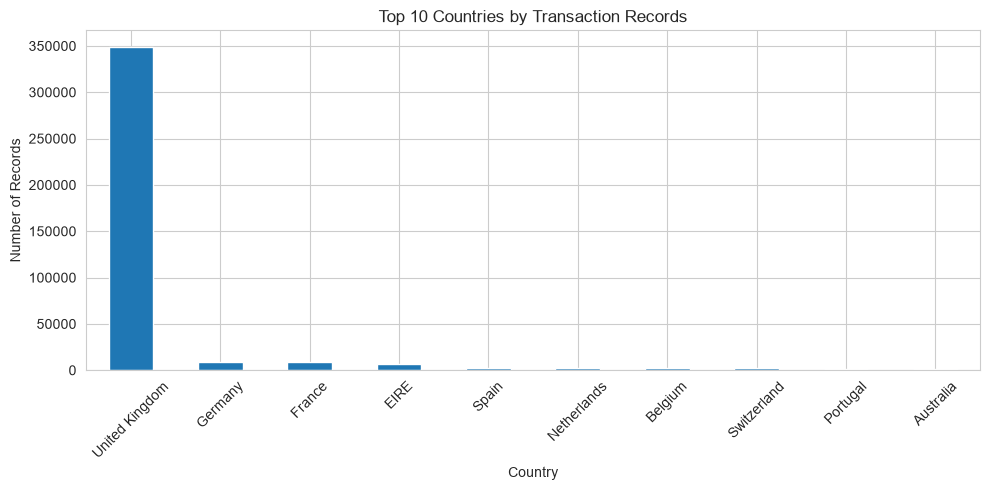

In [28]:
plt.figure(figsize=(10, 5))

df_clean['Country'].value_counts().head(10).plot(
    kind='bar'
)

plt.title("Top 10 Countries by Transaction Records")
plt.xlabel("Country")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [41]:
reference_date = (
    df_clean['InvoiceDate'].max()
    + pd.Timedelta(days=1)
)

rfm = df_clean.groupby('CustomerID').agg({

    'InvoiceDate': lambda x: (
        reference_date - x.max()
    ).days,

    'InvoiceNo': 'nunique',

    'TotalAmount': 'sum'

})

rfm.columns = [
    'Recency',
    'Frequency',
    'Monetary'
]

print("RFM Feature Table Created!")

display(rfm.head(10))

RFM Feature Table Created!


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40
12352,36,8,2506.04
12353,204,1,89.00
12354,232,1,1079.40
12355,214,1,459.40


In [42]:
print("RFM Statistical Summary:")

display(rfm.describe())

print("\nMissing Values:")
print(rfm.isnull().sum())

print("\nTotal Customers:", len(rfm))

RFM Statistical Summary:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000



Missing Values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Total Customers: 4338


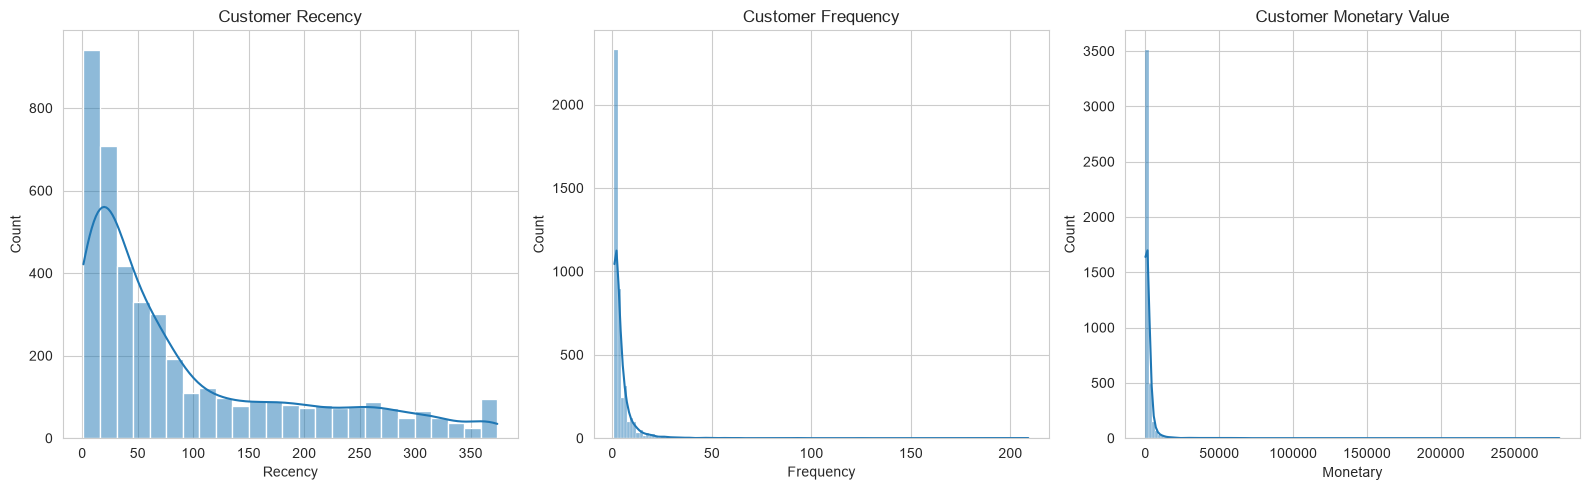

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(rfm['Recency'], kde=True, ax=axes[0])
axes[0].set_title("Customer Recency")

sns.histplot(rfm['Frequency'], kde=True, ax=axes[1])
axes[1].set_title("Customer Frequency")

sns.histplot(rfm['Monetary'], kde=True, ax=axes[2])
axes[2].set_title("Customer Monetary Value")

plt.tight_layout()
plt.show()

In [44]:
from sklearn.preprocessing import StandardScaler

# Log transformation
rfm_log = np.log1p(rfm)

# Standardization
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=rfm.columns,
    index=rfm.index
)

print("Feature Scaling Completed!")

display(rfm_scaled_df.head())

Feature Scaling Completed!


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514


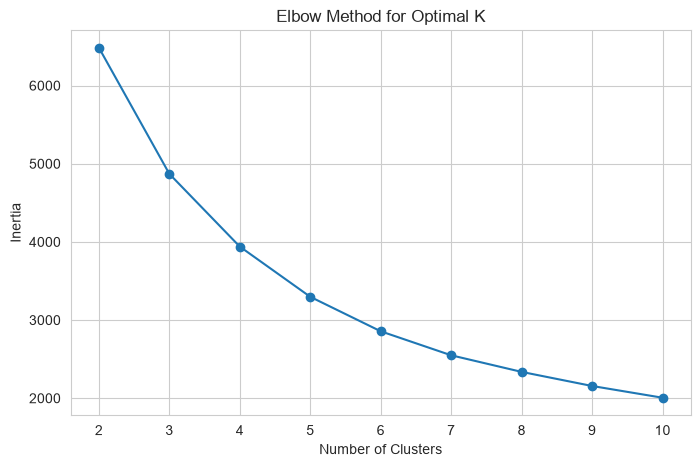

In [45]:
inertia_values = []

K = range(2, 11)

for k in K:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(rfm_scaled_df)

    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(K, inertia_values, marker='o')

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(K)

plt.show()

Clusters: 2, Silhouette Score: 0.4328
Clusters: 3, Silhouette Score: 0.3365
Clusters: 4, Silhouette Score: 0.3375
Clusters: 5, Silhouette Score: 0.3162
Clusters: 6, Silhouette Score: 0.3124
Clusters: 7, Silhouette Score: 0.3092
Clusters: 8, Silhouette Score: 0.3033
Clusters: 9, Silhouette Score: 0.2811
Clusters: 10, Silhouette Score: 0.2767


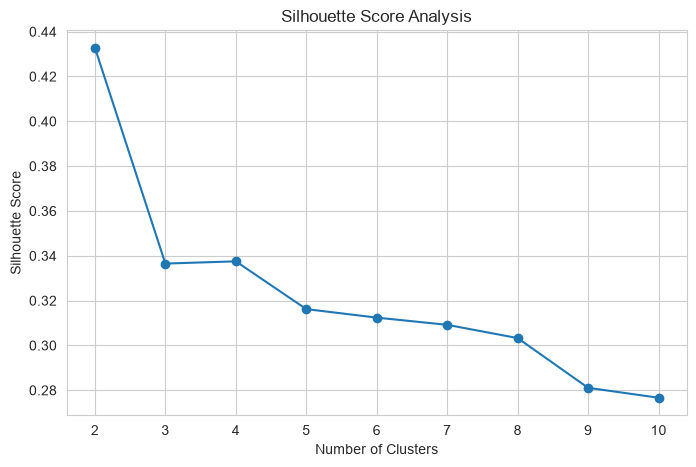

In [46]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled_df)

    score = silhouette_score(
        rfm_scaled_df,
        labels
    )

    silhouette_scores.append(score)

    print(
        f"Clusters: {k}, "
        f"Silhouette Score: {score:.4f}"
    )

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))

plt.show()

In [47]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(
    rfm_scaled_df
)

print("K-Means Clustering Completed!")

display(rfm.head(10))

K-Means Clustering Completed!


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,3
12347,2,7,4310.00,0
12348,75,4,1797.24,3
12349,19,1,1757.55,2
12350,310,1,334.40,1
12352,36,8,2506.04,3
12353,204,1,89.00,1
12354,232,1,1079.40,1
12355,214,1,459.40,1


In [48]:
cluster_summary = rfm.groupby('Cluster').agg({

    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'

}).round(2)

cluster_summary['CustomerCount'] = (
    rfm.groupby('Cluster').size()
)

display(cluster_summary)

,Recency,Frequency,Monetary,CustomerCount
Cluster,,,,
0,12.17,13.75,8088.02,713
1,181.51,1.32,341.00,1622
2,17.70,2.19,557.32,837
3,71.64,4.08,1801.78,1166


In [49]:
cluster_summary['RFM_Value'] = (

    cluster_summary['Recency'].rank(
        ascending=False, pct=True
    )
    +
    cluster_summary['Frequency'].rank(
        ascending=True, pct=True
    )
    +
    cluster_summary['Monetary'].rank(
        ascending=True, pct=True
    )

) / 3

ordered_clusters = (
    cluster_summary['RFM_Value'].sort_values().index
)

segment_names = [
    'At-Risk Customers',
    'Occasional Buyers',
    'Regular Customers',
    'Champions'
]

cluster_to_segment = dict(
    zip(ordered_clusters, segment_names)
)

rfm['Segment'] = rfm['Cluster'].map(
    cluster_to_segment
)

print("Customer Segments Assigned!")

display(rfm.head(15))

Customer Segments Assigned!


,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346,326,1,77183.60,3,Regular Customers
12347,2,7,4310.00,0,Champions
12348,75,4,1797.24,3,Regular Customers
12349,19,1,1757.55,2,Occasional Buyers
12350,310,1,334.40,1,At-Risk Customers
12352,36,8,2506.04,3,Regular Customers
12353,204,1,89.00,1,At-Risk Customers
12354,232,1,1079.40,1,At-Risk Customers
12355,214,1,459.40,1,At-Risk Customers


In [50]:
cluster_summary['RFM_Value'] = (

    cluster_summary['Recency'].rank(
        ascending=False, pct=True
    )
    +
    cluster_summary['Frequency'].rank(
        ascending=True, pct=True
    )
    +
    cluster_summary['Monetary'].rank(
        ascending=True, pct=True
    )

) / 3

ordered_clusters = (
    cluster_summary['RFM_Value'].sort_values().index
)

segment_names = [
    'At-Risk Customers',
    'Occasional Buyers',
    'Regular Customers',
    'Champions'
]

cluster_to_segment = dict(
    zip(ordered_clusters, segment_names)
)

rfm['Segment'] = rfm['Cluster'].map(
    cluster_to_segment
)

print("Customer Segments Assigned!")

display(rfm.head(15))

Customer Segments Assigned!


,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346,326,1,77183.60,3,Regular Customers
12347,2,7,4310.00,0,Champions
12348,75,4,1797.24,3,Regular Customers
12349,19,1,1757.55,2,Occasional Buyers
12350,310,1,334.40,1,At-Risk Customers
12352,36,8,2506.04,3,Regular Customers
12353,204,1,89.00,1,At-Risk Customers
12354,232,1,1079.40,1,At-Risk Customers
12355,214,1,459.40,1,At-Risk Customers


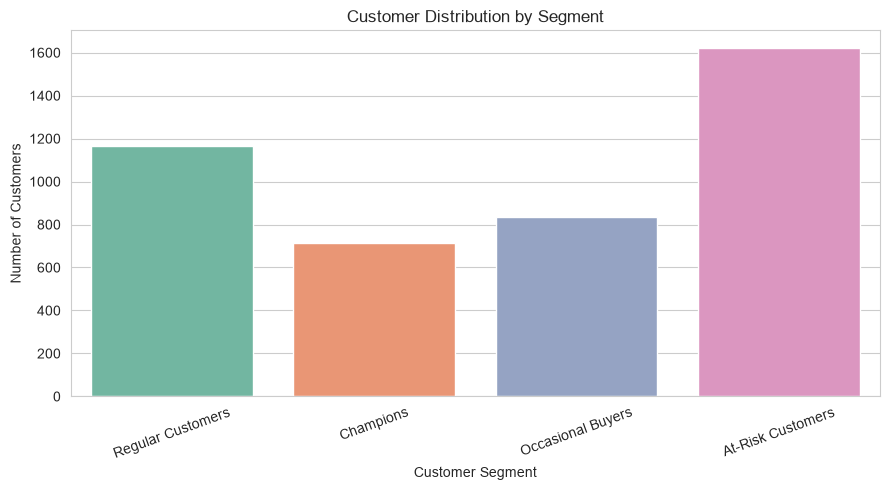

In [51]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm,
    x='Segment',
    hue='Segment',
    palette='Set2',
    legend=False
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [52]:
customer_item_matrix = df_clean.pivot_table(
    index='CustomerID',
    columns='StockCode',
    values='Quantity',
    aggfunc='sum',
    fill_value=0
)

print("Customer-Product Matrix Created!")

print("Matrix Shape:", customer_item_matrix.shape)

display(customer_item_matrix.head())

Customer-Product Matrix Created!
Matrix Shape: (4338, 3665)


StockCode,10002,10080,10120,10125,10133,10135,11001,15030,15034,15036,...,90214V,90214W,90214Y,90214Z,BANK CHARGES,C2,DOT,M,PADS,POST
CustomerID,,,,,,,,,,,,,,,,,,,,,
12346,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12347,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12348,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9
12349,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
12350,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [53]:
from sklearn.metrics.pairwise import cosine_similarity

# Apply log transformation
item_user_matrix = np.log1p(
    customer_item_matrix
).T

# Calculate product similarity
item_similarity = cosine_similarity(
    item_user_matrix
)

# Create similarity DataFrame
item_similarity_df = pd.DataFrame(
    item_similarity,
    index=item_user_matrix.index,
    columns=item_user_matrix.index
)

print("Cosine Similarity Calculated!")

display(item_similarity_df.iloc[:5, :5])

Cosine Similarity Calculated!


StockCode,10002,10080,10120,10125,10133
StockCode,,,,,
10002,1.000000,0.000000,0.028646,0.136343,0.081236
10080,0.000000,1.000000,0.000000,0.037585,0.039525
10120,0.028646,0.000000,1.000000,0.028389,0.071954
10125,0.136343,0.037585,0.028389,1.000000,0.052855
10133,0.081236,0.039525,0.071954,0.052855,1.000000


In [54]:
product_names = (
    df_clean.groupby('StockCode')['Description']
    .agg(lambda x: x.mode().iloc[0])
)

print("Product Name Mapping Created!")

display(product_names.head(10))

Product Name Mapping Created!


StockCode
10002     INFLATABLE POLITICAL GLOBE 
10080        GROOVY CACTUS INFLATABLE
10120                    DOGGY RUBBER
10125         MINI FUNKY DESIGN TAPES
10133    COLOURING PENCILS BROWN TUBE
10135    COLOURING PENCILS BROWN TUBE
11001     ASSTD DESIGN RACING CAR PEN
15030                FAN BLACK FRAME 
15034     PAPER POCKET TRAVELING FAN 
15036       ASSORTED COLOURS SILK FAN
Name: Description, dtype: str

In [55]:
def recommend_products(customer_id, top_n=5):

    if customer_id not in customer_item_matrix.index:
        print("Customer ID not found!")
        return

    # Customer purchase history
    customer_history = customer_item_matrix.loc[
        customer_id
    ]

    purchased_products = customer_history[
        customer_history > 0
    ]

    if purchased_products.empty:
        print("No purchase history available!")
        return

    # Purchase weights
    product_weights = np.log1p(
        purchased_products
    )

    # Calculate recommendation scores
    recommendation_scores = (
        item_similarity_df[purchased_products.index]
        .mul(product_weights, axis=1)
        .sum(axis=1)
    )

    # Exclude already purchased products
    recommendation_scores = recommendation_scores.drop(
        index=purchased_products.index
    )

    # Select top products
    top_products = recommendation_scores.nlargest(
        top_n
    )

    recommendations = pd.DataFrame({

        'StockCode': top_products.index,

        'Product': [
            product_names.get(code, 'Unknown Product')
            for code in top_products.index
        ],

        'SimilarityScore': top_products.values

    })

    return recommendations

In [56]:
sample_customer = customer_item_matrix.index[0]

print("Customer ID:", sample_customer)

print("\nRecommended Products:")

display(
    recommend_products(
        customer_id=sample_customer,
        top_n=5
    )
)

Customer ID: 12346

Recommended Products:


,StockCode,Product,SimilarityScore
0,23165,LARGE CERAMIC TOP STORAGE JAR,8.037345
1,23167,SMALL CERAMIC TOP STORAGE JAR,7.313975
2,22993,SET OF 4 PANTRY JELLY MOULDS,3.594591
3,22666,RECIPE BOX PANTRY YELLOW DESIGN,3.139468
4,22720,SET OF 3 CAKE TINS PANTRY DESIGN,3.079835


In [57]:
recommend_products(
    customer_id=12347,
    top_n=5
)

,StockCode,Product,SimilarityScore
0,21212,PACK OF 72 RETROSPOT CAKE CASES,51.426542
1,23245,SET OF 3 REGENCY CAKE TINS,49.949654
2,20725,LUNCH BAG RED RETROSPOT,47.374805
3,23307,SET OF 60 PANTRY DESIGN CAKE CASES,46.699525
4,22629,SPACEBOY LUNCH BOX,46.596379


In [58]:
business_summary = rfm.groupby('Segment').agg({

    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'

}).round(2)

business_summary['CustomerCount'] = (
    rfm.groupby('Segment').size()
)

display(business_summary)

,Recency,Frequency,Monetary,CustomerCount
Segment,,,,
At-Risk Customers,181.51,1.32,341.00,1622
Champions,12.17,13.75,8088.02,713
Occasional Buyers,17.70,2.19,557.32,837
Regular Customers,71.64,4.08,1801.78,1166


In [59]:
business_recommendations = {

    'Champions':
    'Provide loyalty rewards, exclusive offers, '
    'early product access and VIP benefits.',

    'Regular Customers':
    'Encourage repeat purchases through loyalty '
    'programs and personalized product suggestions.',

    'Occasional Buyers':
    'Use targeted discounts, product bundles '
    'and promotional campaigns.',

    'At-Risk Customers':
    'Send re-engagement campaigns, special discounts '
    'and personalized product recommendations.'

}

for segment in business_summary.index:

    print("\nCustomer Segment:", segment)

    print(
        "Customer Count:",
        business_summary.loc[segment, 'CustomerCount']
    )

    print(
        "Business Strategy:",
        business_recommendations[segment]
    )

    print("-" * 60)


Customer Segment: At-Risk Customers
Customer Count: 1622
Business Strategy: Send re-engagement campaigns, special discounts and personalized product recommendations.
------------------------------------------------------------

Customer Segment: Champions
Customer Count: 713
Business Strategy: Provide loyalty rewards, exclusive offers, early product access and VIP benefits.
------------------------------------------------------------

Customer Segment: Occasional Buyers
Customer Count: 837
Business Strategy: Use targeted discounts, product bundles and promotional campaigns.
------------------------------------------------------------

Customer Segment: Regular Customers
Customer Count: 1166
Business Strategy: Encourage repeat purchases through loyalty programs and personalized product suggestions.
------------------------------------------------------------


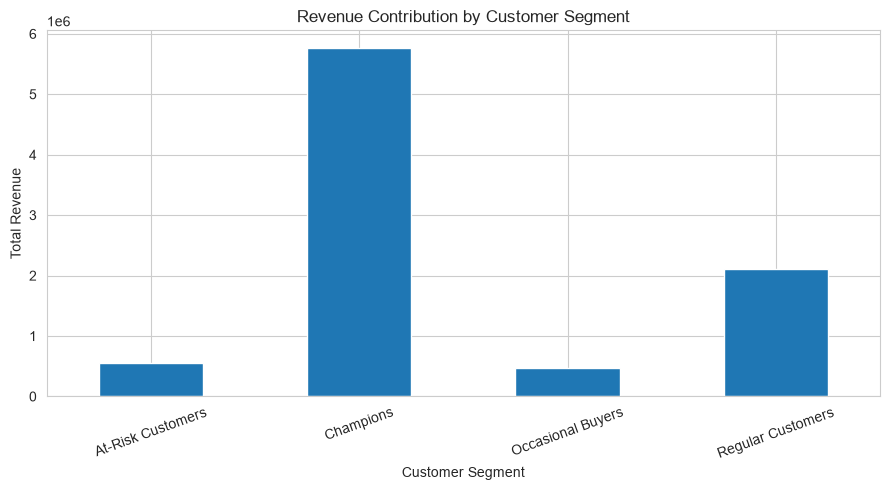

In [60]:
segment_revenue = rfm.groupby('Segment')['Monetary'].sum()

plt.figure(figsize=(9, 5))

segment_revenue.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [61]:
df_clean.to_csv(
    'Cleaned_Online_Retail.csv',
    index=False
)

print("Cleaned Dataset Exported Successfully!")

Cleaned Dataset Exported Successfully!


In [62]:
rfm.to_csv(
    'Customer_Segmentation_Results.csv'
)

print("Customer Segmentation Results Exported!")

Customer Segmentation Results Exported!


In [63]:
business_summary.to_csv(
    'Business_Recommendations_Summary.csv'
)

print("Business Summary Exported!")

Business Summary Exported!


In [64]:
print("=" * 60)

print("E-COMMERCE CUSTOMER SEGMENTATION")
print("AND RECOMMENDATION ANALYSIS")

print("=" * 60)

print("\nTotal Transactions:",
      df_clean['InvoiceNo'].nunique())

print("Total Customers:",
      rfm.shape[0])

print("Total Products:",
      df_clean['StockCode'].nunique())

print("Total Revenue:",
      round(df_clean['TotalAmount'].sum(), 2))

print("\nCustomer Segments:")
print(rfm['Segment'].value_counts())

print("\nClustering Algorithm: K-Means")

print("Recommendation Technique: Cosine Similarity")

print("\nPROJECT COMPLETED SUCCESSFULLY!")

print("=" * 60)

E-COMMERCE CUSTOMER SEGMENTATION
AND RECOMMENDATION ANALYSIS

Total Transactions: 18532
Total Customers: 4338
Total Products: 3665
Total Revenue: 8887208.89

Customer Segments:
Segment
At-Risk Customers    1622
Regular Customers    1166
Occasional Buyers     837
Champions             713
Name: count, dtype: int64

Clustering Algorithm: K-Means
Recommendation Technique: Cosine Similarity

PROJECT COMPLETED SUCCESSFULLY!


# Conclusion

The E-Commerce Customer Segmentation and Recommendation Analysis project demonstrates the application of machine learning in understanding customer purchasing behavior.

The UCI Online Retail dataset was cleaned and processed to generate customer-level Recency, Frequency and Monetary (RFM) features.

K-Means clustering was implemented to identify different customer segments based on their purchasing patterns. The Elbow Method and Silhouette Analysis were used to evaluate the clustering configuration.

PCA was applied to visualize the customer clusters in two dimensions.

A basic product recommendation system was developed using Cosine Similarity to recommend products based on customers' previous purchasing behavior.

Finally, business recommendations were developed for different customer segments to support customer retention, personalized marketing and improved customer engagement.

**Technologies Used:** Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn and Jupyter Notebook.

**Project Status:** Completed.

In [65]:
import os

files = [
    'Cleaned_Online_Retail.csv',
    'Customer_Segmentation_Results.csv',
    'Business_Recommendations_Summary.csv'
]

print("PROJECT OUTPUT FILES")
print("-" * 40)

for file in files:
    if os.path.exists(file):
        print(f"✓ {file} - {os.path.getsize(file) / 1024:.2f} KB")
    else:
        print(f"✗ {file} - NOT FOUND")

PROJECT OUTPUT FILES
----------------------------------------
✓ Cleaned_Online_Retail.csv - 37162.52 KB
✓ Customer_Segmentation_Results.csv - 167.43 KB
✓ Business_Recommendations_Summary.csv - 0.21 KB
